#### Setup

In [1]:
import os, shutil, subprocess, sys, textwrap
from pathlib import Path

from IPython.display import SVG, display

from dvc_dat import Dat
from dvc_dat.ledger import Ledger, bump

demos_path = Path(globals().get("demos_path", Path.cwd()))   # survives the chdir
os.chdir(demos_path)
scratch_path = demos_path / "scratch/q-dats"
shutil.rmtree(scratch_path, ignore_errors=True)   # a re-run starts clean
for module_name in [m for m in sys.modules if m.split(".")[0] == "mymodule"]:
    del sys.modules[module_name]
sys.path[:] = [p for p in sys.path if p != str(scratch_path)]

scratch_path.mkdir(parents=True)
os.chdir(scratch_path)
git_cmd = ["git", "-c", "user.name=demo", "-c", "user.email=demo@example.com"]
Path(".gitignore").write_text(".dat/\ndata/\n")
Path("pyproject.toml").write_text('[project]\nname = "q-dats"\nversion = "0.1.0"\n')
for args in (["init", "-q"], ["add", "."], ["commit", "-q", "-m", "q-dats"]):
    subprocess.run(git_cmd + args, check=True)
sys.path.insert(0, str(scratch_path))
L = Ledger(create=True)              # .datconfig.yaml + .dat/ledger
Dat.manager = None                   # the dat world reloads from this folder


def show(name):
    """The figure `<name>.svg` beside this notebook."""
    display(SVG(filename=str(demos_path / f"{name}.svg")))

# Quick: dats

A dat is a handle for a folder of arbitrary data, derived from and
specified by a recursive dictionary of parameters: its spec. On a
ledger it is also a value: sealed, loaded, memoized, found.

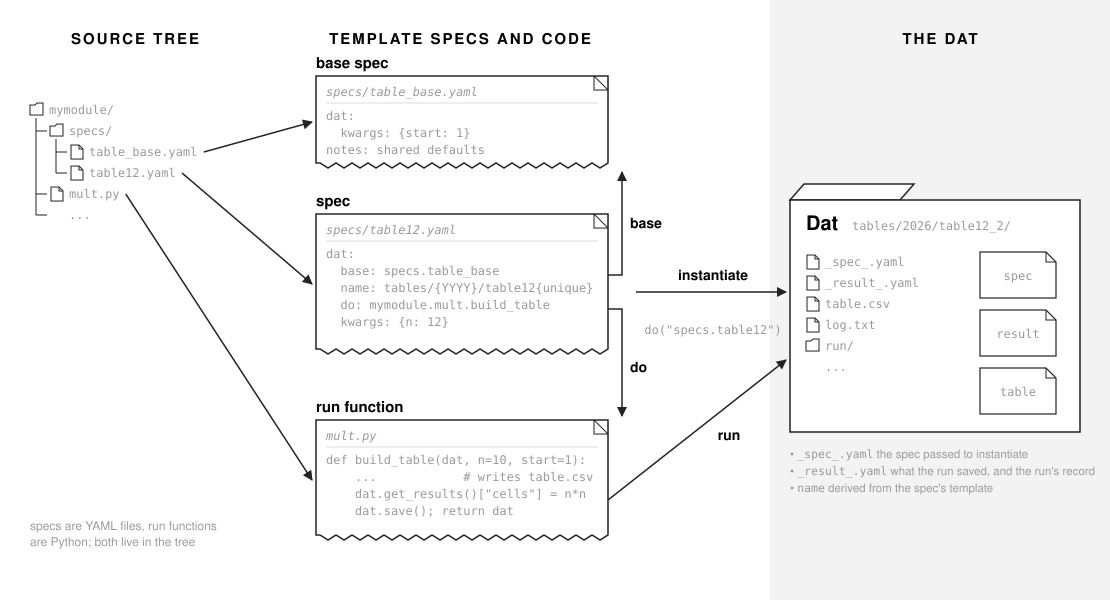

In [2]:
show("q-dats")

## A Dat is a folder with a spec

A spec is a recursive dict of parameters; its `dat:` part is what
the dat system reads. `do:` names the run function, `kwargs:` its
arguments, `base:` a spec to inherit, `name:` a folder template.

#### Setup

In [3]:
# the files: a run function in mult.py, two template specs in specs/
module_path = Path("mymodule")
(module_path / "specs").mkdir(parents=True)
(module_path / "mult.py").write_text('''\
import csv
from pathlib import Path


def write_table(folder, n=10, start=1):
    """`table.csv`, the n x n multiplication table from `start`; its cell count."""
    numbers = range(start, start + n)
    with open(Path(folder, "table.csv"), "w", newline="") as f:
        csv.writer(f).writerows([[a * b for b in numbers] for a in numbers])
    return n * n


def build_table(dat, n=10, start=1):
    """The run function: `do` calls it with the new dat and the spec's kwargs."""
    cells = write_table(dat.get_path(), n, start)
    Path(dat.get_path(), "log.txt").write_text(f"{n} x {n} from {start}\\n")
    dat.get_results()["cells"] = cells
    dat.save()
    return dat
''')
(module_path / "specs/table_base.yaml").write_text('''\
dat:
  kwargs: {start: 1}
notes: shared defaults
''')
(module_path / "specs/table12.yaml").write_text('''\
dat:
  base: specs.table_base
  name: tables/{YYYY}/table12{unique}
  do: mymodule.mult.build_table
  kwargs: {n: 12}
''');

Mounting `specs/` makes `specs/table12.yaml` answer to `specs.table12`.
Making a dat from a spec is three steps: instantiate, run, save.

## 1. Instantiate

`Dat.create` merges the base under the spec, fills the name template
once, makes the folder and writes `_spec_.yaml`. Nothing runs.

In [4]:
Dat.do.mount(folder="mymodule/specs", at="specs")   # the folder tree of specs: a spec is found by name
table12_dat = Dat.create(spec="specs.table12")      # the Dat object, and its folder on disk
table12_path = Path(table12_dat.get_path())
print("dat:", repr(table12_dat))   # dat: <Dat: tables/2026/table12>
print("files:", sorted(os.listdir(table12_path)))   # files: ['_spec_.yaml']
print("_spec_.yaml:\n" + textwrap.indent((table12_path / "_spec_.yaml").read_text(), "    "))
# _spec_.yaml: kwargs {start: 1, n: 12}; no base:; name: the template

dat: <Dat: tables/2026/table12>
files: ['_spec_.yaml']
_spec_.yaml:
    dat:
      kwargs:
        start: 1
        n: 12
      name: tables/{YYYY}/table12{unique}
      do: mymodule.mult.build_table
      kind: dvc_dat.core.Dat
    notes: shared defaults



The spec keeps `name:` as its template; the folder it filled to is
the dat's name, and `{unique}` counts up when the folder is taken.

## 2. Run

`Dat.do(dat)` calls the run function with the dat and the spec's kwargs,
in place. The folder gains whatever the run wrote, `_result_.yaml`
(what the run stored) and `run/` (when, where, on which commit).

In [5]:
Dat.do(table12_dat)   # executes build_table in mult.py for this dat

print("files:", sorted(os.listdir(table12_path)))
# files: ['_result_.yaml', '_spec_.yaml', 'log.txt', 'run', 'table.csv']
print("cells:", table12_dat.get_results()["cells"])   # cells: 144
print("table.csv:\n" + textwrap.indent("\n".join((table12_path / "table.csv").read_text().splitlines()[:3]), "    "))
# table.csv: rows 1..12, 2..24, 3..36
print("_result_.yaml:\n" + textwrap.indent((table12_path / "_result_.yaml").read_text(), "    "))
# _result_.yaml: cells, and under dat: what the seal recorded

files: ['_result_.yaml', '_spec_.yaml', 'log.txt', 'run', 'table.csv']
cells: 144
table.csv:
    1,2,3,4,5,6,7,8,9,10,11,12
    2,4,6,8,10,12,14,16,18,20,22,24
    3,6,9,12,15,18,21,24,27,30,33,36
_result_.yaml:
    dat:
      dependencies: {}
      standing: referenceable
      hash: functional
      sha256: sha256:4a1f195a93d4863c561b129b857351dd40ae67df33d6a9cab8bfb2f575be36dc
    cells: 144



## 3. Save it as a value

On a ledger a dat is a value: sealed under a name, loaded back,
found by its preds. Nothing runs here. `path_to_table_dat` reads
the folder's spec kwargs and result as preds; `seal` stores the
folder; `load` brings it back.

Today this takes a class. The ledger's `Dat` is a `Value` over a
folder, but it is not the `Dat` that `do` returns, and `load`
refuses a folder whose spec names `dvc_dat.core.Dat` unless the
class accepts that kind; `TableDat` does, and declares the preds.
Whether a dat should be a value by itself is DAT 1038.

In [6]:
(module_path / "table_dat.py").write_text('''\
from pathlib import Path

import yaml

from dvc_dat.ledger import Dat, ledger_class, ledger_fn

from mymodule.mult import write_table


@ledger_class(preds=("n", "start", "cells"))
class TableDat(Dat):
    """A dat that is a value: the folder `_spec_.yaml`, `_result_.yaml`, `table.csv`."""

    @classmethod
    def kind_ok(cls, kind):
        """`do` made it, so its `_spec_` says `dvc_dat.core.Dat`."""
        return kind == "dvc_dat.core.Dat" or super().kind_ok(kind)


def path_to_table_dat(path) -> TableDat:
    """The dat already in `path`, as a value; nothing runs. Its kwargs and result are its preds."""
    spec = yaml.safe_load(Path(path, "_spec_.yaml").read_text())
    result = yaml.safe_load(Path(path, "_result_.yaml").read_text())
    table_dat = TableDat(Path(path))
    table_dat.preds.update(spec["dat"]["kwargs"])
    table_dat.preds["cells"] = result["cells"]
    return table_dat


@ledger_fn
def table(rev, *, spec: dict, path: Path) -> TableDat:
    """The table constructor: the run itself. `spec` is the question, `path` the folder it fills."""
    cells = write_table(path, **spec["dat"]["kwargs"])
    (path / "_spec_.yaml").write_text(yaml.safe_dump(spec))
    (path / "_result_.yaml").write_text(yaml.safe_dump({"cells": cells}))
    return path_to_table_dat(path)
''')
from mymodule.table_dat import TableDat, path_to_table_dat

sealed_dat = path_to_table_dat(table12_path)   # the dat step 2 ran
with L.transaction(by="human:dan") as t:
    sealed_dat.seal(t, name="tables/table12")
print("dat:", repr(sealed_dat), " sealed:", sealed_dat.sealed)   # dat: <TableDat tables/table12>  sealed: <the seal's moment>

loaded_dat = L.at().load("tables/table12")
print("files:", sorted(p.name for p in loaded_dat.path.iterdir()))
# files: ['_result_.yaml', '_spec_.yaml', 'log.txt', 'run', 'table.csv']
print("preds:", dict(sorted(loaded_dat.preds.items())))
# preds: {'cells': '144', 'n': '12', 'start': '1'}

dat: <TableDat tables/table12>  sealed: 2026-10-25T19:50:54Z
files: ['_result_.yaml', '_spec_.yaml', 'log.txt', 'run', 'table.csv']
preds: {'cells': '144', 'n': '12', 'start': '1'}


Sealing sent the files to the art store by their hashes; the
manifest naming them is the value's bytes. `load` rebuilds the
folder from the store; it does not run anything.

## Execution in practice: all done in one step

`Dat.do("specs.table12")` is steps 1 and 2: it instantiates the spec,
runs the dat, and returns what the run function returned.

In [7]:
again_dat = Dat.do("specs.table12")
print("dat:", repr(again_dat))   # dat: <Dat: tables/2026/table12_2>
print("files:", sorted(os.listdir(again_dat.get_path())))
# files: ['_result_.yaml', '_spec_.yaml', 'log.txt', 'run', 'table.csv']

dat: <Dat: tables/2026/table12_2>
files: ['_result_.yaml', '_spec_.yaml', 'log.txt', 'run', 'table.csv']


All three steps at once is a ledger function: `table(rev, *, spec,
path)` builds a table dat under `@ledger_fn`. The spec is the
question, and the answer is remembered; a ledger function runs
committed, mounted code, in a sandbox. (Under DAT 1038 this is
`L.at().do(spec)`, one operator for every spec, no function of
your own.)

In [8]:
subprocess.run(git_cmd + ["add", "mymodule"], check=True)
subprocess.run(git_cmd + ["commit", "-q", "-m", "mymodule"], check=True)
with L.transaction(by="human:dan", why="mount mymodule", lock=5) as t:   # bump reads, then writes
    t.add("db/mount/mymodule", "db/root", "mymodule")
    t.add("db/mount/mymodule", "db/repo", "q-dats")
    bump(t, "code/q-dats", "minor", confirm=lambda old, new: True)

table12_spec_record = Dat.do.resolve("specs.table12")
spec_dat = L.at().run("mymodule.table_dat.table", spec=table12_spec_record)
print("dat:", repr(spec_dat))   # dat: <TableDat anonymous/Dat>: no name given

top_id = L.at().id
again_spec_dat = L.at().run("mymodule.table_dat.table", spec=table12_spec_record)
print("same subject:", again_spec_dat.subject == spec_dat.subject,
      " nothing written:", L.at().id == top_id)   # same subject: True  nothing written: True: a hit

dat: <TableDat anonymous/Dat>


same subject: True  nothing written: True


The same spec is the same question: the second run is a memo hit,
nothing runs and nothing is written.

## Finding dats

In [9]:
for n in (5, 9):
    L.at().run("mymodule.table_dat.table",
               spec={"dat": {"do": "mymodule.mult.build_table", "kwargs": {"n": n, "start": 1}}})
print("cells:", L.at().select(("n", "cells"), kind=TableDat))
# cells: [('12', '144'), ('12', '144'), ('5', '25'), ('9', '81')]: table12 sealed from do's folder, then by the constructor

cells: [('12', '144'), ('12', '144'), ('5', '25'), ('9', '81')]


Spec kwargs and results are preds, so a query over them is an
ordinary ledger query.